#Day 34 - Prediksi Lulus / Tidak Lulus

Sekolah ingin **mengidentifikasi sejak dini** siswa yang berisiko tidak lulus, agar bisa diberi bimbingan tambahan. Di notebook ini kita membuat label "lulus" dari nilai ujian, mengubah data kategori menjadi angka, lalu melatih Decision Tree dan Random Forest untuk memprediksinya.

> 🎯 **Tujuan Pembelajaran**
> - Membuat **target buatan** (`lulus`) dari beberapa kolom nilai.
> - **Encoding** variabel kategori menjadi numerik.
> - Melatih **Decision Tree** & **Random Forest**.
> - Membaca **feature importance** & **confusion matrix**.

## Tentang Dataset

Kita memakai **Students Performance in Exams**.

- **Sumber:** [Kaggle — spscientist/students-performance-in-exams](https://www.kaggle.com/datasets/spscientist/students-performance-in-exams)
- **Target buatan:** `lulus` = 1 jika rata-rata (math + reading + writing) ≥ 60, selain itu 0.

| Kolom | Arti |
|-------|------|
| `gender` | Jenis kelamin |
| `race/ethnicity` | Kelompok etnis (group A–E) |
| `parental level of education` | Pendidikan orang tua |
| `lunch` | Tipe makan siang (standar / berkurang) |
| `test preparation course` | Kursus persiapan ujian (none/completed) |
| `math score` | Nilai matematika |
| `reading score` | Nilai membaca |
| `writing score` | Nilai menulis |

## Import Library

- **pandas / numpy** → olah data.
- **matplotlib / seaborn** → grafik.
- **scikit-learn** → encoding, split, Decision Tree, Random Forest, dan metrik.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, ConfusionMatrixDisplay

##Import Dataset

In [4]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d spscientist/students-performance-in-exams

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/spscientist/students-performance-in-exams
License(s): unknown
100% 8.70k/8.70k [00:00<00:00, 7.04MB/s]



## Eksplorasi Awal Dataset

In [5]:
df = pd.read_csv('students-performance-in-exams.zip')
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [8]:
df.info()
print(f'Banyak baris: {df.shape[0]}')
print(f'Banyak kolom: {df.shape[1]}')
print(f'Banyak nilai null: {df.isna().sum().sum()}')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB
Banyak baris: 1000
Banyak kolom: 8
Banyak nilai null: 0


**Interpretasi:**

- Ada 5 kolom kategori (teks) dan 3 kolom nilai ujian. Belum ada kolom target — kita akan membuatnya sendiri dari rata-rata tiga nilai.
-  Nama kolom memakai spasi (mis. `math score`). Kita akan mengaksesnya dengan tanda kurung siku. Tidak ada nilai kosong.
- Data bersih, tanpa missing value. Kita bisa langsung membuat target.

## Creating Target

In [9]:
df['rata_rata_nilai'] = (df['math score'] + df['reading score'] + df['writing score']) / 3
df['lulus'] = np.where(df['rata_rata_nilai'] >= 60, 1, 0)

print(df['lulus'].value_counts())
df.head()

lulus
1    715
0    285
Name: count, dtype: int64


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,rata_rata_nilai,lulus
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667,1
1,female,group C,some college,standard,completed,69,90,88,82.333333,1
2,female,group B,master's degree,standard,none,90,95,93,92.666667,1
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333,0
4,male,group C,some college,standard,none,76,78,75,76.333333,1


**Interpretasi:**

-  Sebagian besar siswa lulus (rata-rata ≥ 60), tetapi ada porsi yang tidak lulus — inilah kelompok yang ingin kita kenali lebih awal.

## Eksploratory Data Analisis dan Visualisasi

### a) Jumlah Siswa Lulus vs Tidak Lulus

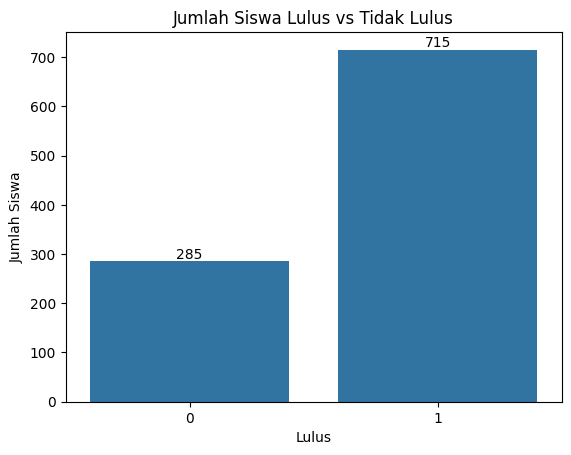

In [12]:
ax = sns.countplot(data=df, x='lulus')
ax.bar_label(ax.containers[0])
ax.set_title('Jumlah Siswa Lulus vs Tidak Lulus')
ax.set_xlabel('Lulus')
ax.set_ylabel('Jumlah Siswa')
plt.show()

**Interpretasi:**

-  Kelas Imbalanced
- Lebih banyak yang lulus
- Perhatikan nilai Recall pada evaluasi, agar siswa yang beriko `tidak lulus` tidak terlewat



### b) Pengaruh kursus Persiapan terhadap Kelulusan Siswa

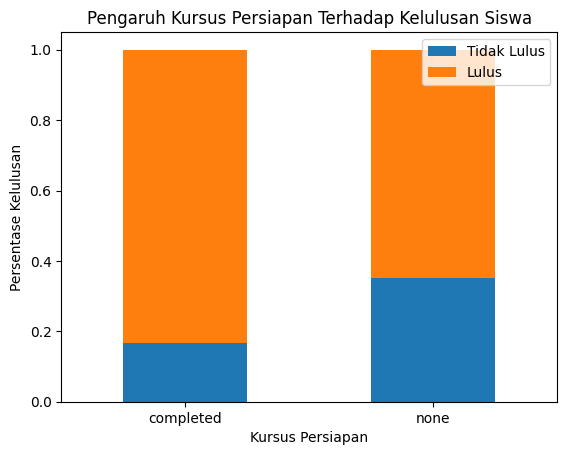

In [23]:
ct = pd.crosstab(df['test preparation course'], df['lulus'], normalize='index')
ct.plot(kind='bar', stacked=True)
plt.title('Pengaruh Kursus Persiapan Terhadap Kelulusan Siswa')
plt.xlabel('Kursus Persiapan')
plt.ylabel('Persentase Kelulusan')
plt.legend(['Tidak Lulus', 'Lulus'])
plt.xticks(rotation=0)

plt.show()

**Interpretasi:**

- Siswa yang Menyelesaikan Kursus (completed):
  - Proporsi siswa yang Lulus (bagian oranye) jauh lebih besar, mencapai sekitar 83% hingga 84% (karena bagian "Tidak Lulus" hanya sekitar 0,16 atau 16%).   
  - Hal ini menunjukkan bahwa mengikuti kursus persiapan sangat membantu meningkatkan peluang siswa untuk lulus.   
  
- Siswa yang Tidak Mengikuti Kursus (none):
  - Proporsi siswa yang Tidak Lulus (bagian biru) meningkat secara signifikan, yaitu sekitar 35% (0,35).   
  - Akibatnya, persentase siswa yang Lulus pada kelompok ini menurun menjadi sekitar 65% saja.

### c) Distribusi rata rata nilai per Kelompok Lulus

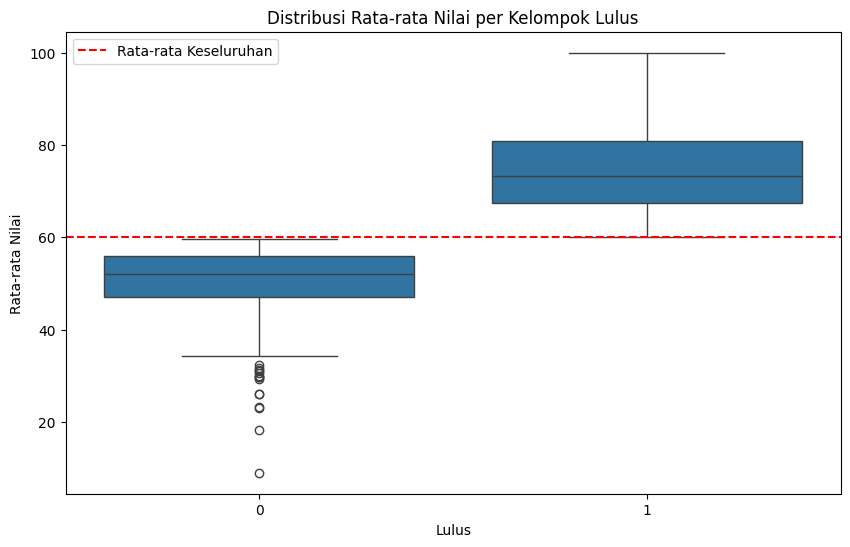

In [27]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='lulus', y='rata_rata_nilai', data=df)
plt.title('Distribusi Rata-rata Nilai per Kelompok Lulus')
plt.xlabel('Lulus')
plt.ylabel('Rata-rata Nilai')
plt.axhline(60, color='red', linestyle='--', label='Rata-rata Keseluruhan')
plt.legend()
plt.show()
#

**Interpretasi:**

  - Kelompok 0 (Tidak Lulus):
    - Sebagian besar siswa yang tidak lulus memiliki rata-rata nilai di bawah garis merah (rata-rata keseluruhan 60).   
    - Nilai median (garis tengah dalam kotak) kelompok ini berada di sekitar angka 52.
    - Terdapat juga beberapa nilai pencilan (outliers) yang turun hingga di bawah 20.   
    
  - Kelompok 1 (Lulus):
    - Seluruh siswa yang lulus memiliki distribusi nilai yang jauh lebih tinggi, di mana sebagian besar berada di atas garis merah (60).   
    - Nilai median kelompok ini berada di sekitar angka 73, dengan nilai tertinggi mencapai 100.   

## Preprocessing ( Encoding & Splitting )

Model hanya mengerti angka, jadi ubah kolom kategori menjadi angka dengan **LabelEncoder**.

Penting: **buang** kolom nilai mentah & `rata_rata` dari fitur, karena target dihitung langsung dari sana (kalau dipakai, model akan 'curang' / kebocoran target).

In [28]:
df_model = df.copy()

cat_cols = ['gender', 'race/ethnicity',
            'parental level of education',
            'lunch', 'test preparation course']

encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    encoders[col] = le

df_model

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,rata_rata_nilai,lulus
0,0,1,1,1,1,72,72,74,72.666667,1
1,0,2,4,1,0,69,90,88,82.333333,1
2,0,1,3,1,1,90,95,93,92.666667,1
3,1,0,0,0,1,47,57,44,49.333333,0
4,1,2,4,1,1,76,78,75,76.333333,1
...,...,...,...,...,...,...,...,...,...,...
995,0,4,3,1,0,88,99,95,94.000000,1
996,1,2,2,0,1,62,55,55,57.333333,0
997,0,2,2,0,0,59,71,65,65.000000,1
998,0,3,4,1,0,68,78,77,74.333333,1


In [29]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,rata_rata_nilai,lulus
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667,1
1,female,group C,some college,standard,completed,69,90,88,82.333333,1
2,female,group B,master's degree,standard,none,90,95,93,92.666667,1
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333,0
4,male,group C,some college,standard,none,76,78,75,76.333333,1


In [30]:
# Pisahkan X dan y
X = df_model[cat_cols]
y = df_model['lulus']

# Splitting data
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

print(f'Banyak data train: {X_train.shape[0]}')
print(f'Banyak data test: {X_test.shape[0]}')
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Banyak data train: 800
Banyak data test: 200
lulus
1    0.715
0    0.285
Name: proportion, dtype: float64
lulus
1    0.715
0    0.285
Name: proportion, dtype: float64


In [31]:
X_train.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course
84,1,3,2,0,1
424,1,1,4,0,1
649,0,3,4,1,0
292,1,2,5,1,0
534,1,1,2,1,0


**Interpretasi:**
- Gunakan Dataset terbaru yang sudah di encoding
- Memprediksi kelulusan hanya dari **latar belakang siswa** (gender, etnis, pendidikan ortu, makan siang, kursus) — bukan dari nilainya. Ini tantangan yang lebih nyata: bisakah faktor latar belakang memprediksi keberhasilan?

## Modelling


Latih dua model pohon: **Decision Tree** (satu pohon) dan **Random Forest** (banyak pohon).

In [50]:
dt = DecisionTreeClassifier(max_depth= 5, random_state=42)
dt.fit(X_train, y_train)
pred_dt = dt.predict(X_test)

rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)


print("Akurasi Decision Tree:", round(accuracy_score(y_test, pred_dt), 3))
print("Akurasi Random Forest:", round(accuracy_score(y_test, pred_rf), 3))

Akurasi Decision Tree: 0.645
Akurasi Random Forest: 0.715


**Interpretasi:**
-  Karena hanya memakai fitur latar belakang, akurasi tidak akan setinggi kalau kita pakai nilai mentah. Ini realistis — latar belakang hanya sebagian dari cerita

## Evaluasi Model


In [51]:
print("=== Decision Tree ===")
print(classification_report(y_test, pred_dt, target_names=["Tidak Lulus (0)", "Lulus (1)"]))
print("=== Random Forest ===")
print(classification_report(y_test, pred_rf, target_names=["Tidak Lulus (0)", "Lulus (1)"]))

=== Decision Tree ===
                 precision    recall  f1-score   support

Tidak Lulus (0)       0.34      0.26      0.30        57
      Lulus (1)       0.73      0.80      0.76       143

       accuracy                           0.65       200
      macro avg       0.54      0.53      0.53       200
   weighted avg       0.62      0.65      0.63       200

=== Random Forest ===
                 precision    recall  f1-score   support

Tidak Lulus (0)       0.50      0.30      0.37        57
      Lulus (1)       0.76      0.88      0.82       143

       accuracy                           0.71       200
      macro avg       0.63      0.59      0.59       200
   weighted avg       0.69      0.71      0.69       200



**Interpretasi:**

1. Decision Tree


  - Akurasi (65%): Model ini berhasil menebak status kelulusan dengan benar sebanyak 65% dari total 200 data pengujian (130 benar, 70 salah).

  - Kelas "Tidak Lulus" (0):

    - Precision (0.34): Dari semua siswa yang diprediksi model tidak lulus, hanya 34% yang benar-benar tidak lulus; sisanya salah prediksi (sebenarnya lulus).

    - Recall (0.26): Dari total 57 siswa yang aslinya tidak lulus, model hanya mampu mendeteksi 26% di antaranya.

    - F1-score (0.30): Menunjukkan performa yang rendah dan kurang baik dalam mengenali kelompok siswa yang tidak lulus.

  - Kelas "Lulus" (1):
    
    - Precision (0.73): Dari semua siswa yang diprediksi lulus, 73% memang benar-benar lulus.

    - Recall (0.80): Dari total 143 siswa yang aslinya lulus, model berhasil mendeteksi 80% di antaranya.

    - F1-score (0.76): Performa model cukup baik pada kelas ini karena jumlah datanya lebih banyak.

2. Random Forest

  - Akurasi (71%): Model ini memiliki akurasi yang lebih tinggi, yaitu berhasil menebak dengan benar sebanyak 71% dari 200 data pengujian (peningkatan dari Decision Tree).

  - Kelas "Tidak Lulus" (0):

    - Precision (0.50): Dari semua siswa yang diprediksi tidak lulus, separuhnya (50%) benar-benar tidak lulus (mengalami peningkatan kualitas tebakan dibanding Decision Tree).

    - Recall (0.30): Dari total 57 siswa yang aslinya tidak lulus, model berhasil mendeteksi 30%.

    - F1-score (0.37): Sedikit lebih baik dari Decision Tree, meskipun masih tergolong rendah karena jumlah data siswa tidak lulus lebih sedikit (imbalanced data).

  - Kelas "Lulus" (1):

    - Precision (0.76): Dari semua siswa yang diprediksi lulus, 76% benar-benar lulus.

    - Recall (0.88): Model sangat andal dalam menjaring siswa yang benar-benar lulus, yakni mencapai 88% dari total 143 siswa.

    - F1-score (0.82): Menunjukkan performa yang sangat solid untuk kelas siswa lulus.

Kesimpulan Akhir

- Model Terbaik: Random Forest secara keseluruhan lebih unggul dibandingkan Decision Tree, dilihat dari akurasi yang lebih tinggi (71% vs 65%) serta skor f1-score yang lebih baik di kedua kelas.

- Kendala Model (Data Tidak Seimbang): Kedua model sama-sama kesulitan mengenali kelas "Tidak Lulus" (0) secara optimal karena jumlah datanya lebih sedikit (57 data) dibandingkan kelas "Lulus" (1) yang mencapai 143 data. Model cenderung lebih "jago" menebak siswa yang lulus.

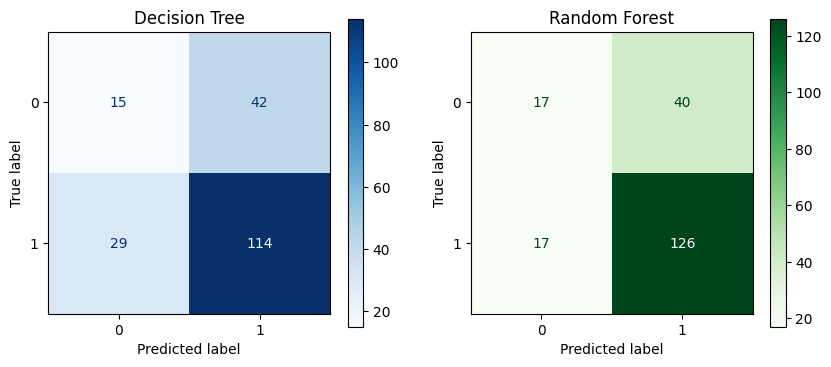

In [53]:
fig, axes = plt.subplots(nrows = 1,ncols = 2,figsize = (10,4))
ConfusionMatrixDisplay.from_estimator(dt, X_test, y_test, ax=axes[0], cmap='Blues')
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, ax=axes[1], cmap='Greens')
axes[0].set_title('Decision Tree')
axes[1].set_title('Random Forest')
plt.show()

1. Confusion Matrix: - Decision Tree
    -  True Negative (TN = 15): Model dengan benar memprediksi 15 siswa sebagai "Tidak Lulus (0)" padahal aslinya memang tidak lulus.   
    - False Positive (FP = 42): Model salah memprediksi 42 siswa sebagai "Lulus (1)", padahal aslinya mereka tidak lulus. Ini adalah kesalahan terbesar model ini (banyak siswa gagal tapi dibilang lulus).   
    - False Negative (FN = 29): Model salah memprediksi 29 siswa sebagai "Tidak Lulus (0)", padahal aslinya mereka lulus.   
    - True Positive (TP = 114): Model dengan tepat memprediksi 114 siswa sebagai "Lulus (1)" dan memang aslinya lulus.   


2. Confusion Matrix: - Random Forest
      - True Negative (TN = 17): Model berhasil mengenali 17 siswa yang benar-benar tidak lulus (sedikit lebih baik dari Decision Tree).   
      - False Positive (FP = 40): Terdapat 40 siswa yang aslinya tidak lulus, namun diprediksi lulus oleh model (sedikit menurun dibanding Decision Tree).  
      - False Negative (FN = 17): Terdapat 17 siswa yang aslinya lulus, namun salah diprediksi tidak lulus oleh model (berkurang jauh dari 29 pada Decision Tree).
      - True Positive (TP = 126): Model sukses menebak 126 siswa yang benar-benar lulus (meningkat dari 114 pada Decision Tree).   
      
Kesimpulan Utama dari Confusion Matrix:

  - Peningkatan Performa (Random Forest vs Decision Tree):
    - Random Forest berhasil mendeteksi siswa lulus lebih banyak (126 berbanding 114 orang).   
    - Random Forest juga menekan kesalahan prediksi siswa lulus yang disangka tidak lulus (False Negative turun drastis dari 29 menjadi 17).   
  - Kelemahan Bersama:
    - Kedua model sama-sama memiliki angka False Positive yang tinggi (42 dan 40).
    - Artinya, kedua model masih cukup sering "terkecoh" dengan meloloskan prediksi siswa yang sebenarnya gagal (Tidak Lulus). Hal ini disebabkan oleh jumlah data siswa tidak lulus yang lebih sedikit (imbalance)

## Feature Importance ( Random Forest )

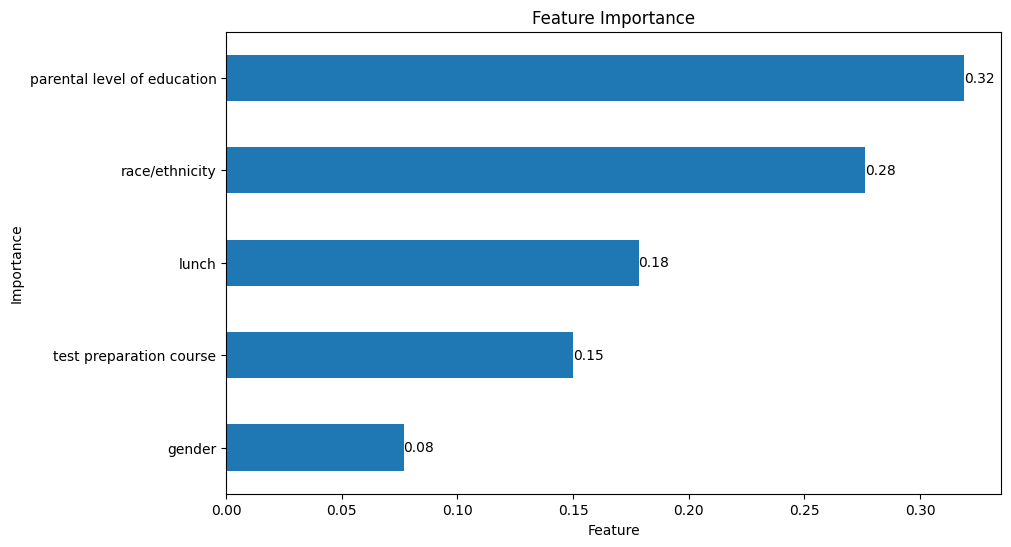

parental level of education    0.32
race/ethnicity                 0.28
lunch                          0.18
test preparation course        0.15
gender                         0.08
dtype: float64


In [61]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=True)
imp.plot(kind='barh', figsize=(10, 6))
plt.title('Feature Importance')
plt.ylabel('Importance')
plt.xlabel('Feature')
for i, v in enumerate(imp):
    plt.text(v, i, f'{v:.2f}', va='center')
plt.show()

print(imp.sort_values(ascending=False).round(2))

**Interpretasi:**

- parental level of education (0.32 atau 32%): Ini adalah faktor yang paling berpengaruh (peringkat pertama) bagi model. Tingkat pendidikan orang tua memegang peran terbesar dalam menentukan hasil tebakan atau prediksi model.

- race/ethnicity (0.28 atau 28%): Menjadi faktor terpenting kedua yang memiliki bobot pengaruh cukup tinggi dalam keputusan model.

- lunch (0.18 atau 18%): Faktor sosio-ekonomi ini memiliki pengaruh tingkat menengah terhadap prediksi model.

- Test preparation course (0.15 atau 15%): Keikutsertaan dalam kursus persiapan memberikan dampak yang moderat bagi model dalam mengenali pola data.

- gender (0.08 atau 8%): Merupakan faktor dengan pengaruh paling kecil dibandingkan variabel lainnya bagi model.

Kesimpulan Utama:

Model machine learning ini paling banyak mengandalkan latar belakang keluarga dan demografi (pendidikan orang tua serta ras/etnis) sebagai acuan utama dalam membuat prediksi, sementara faktor jenis kelamin (gender) menjadi informasi yang paling sedikit diperhitungkan oleh model.

## Kesimpulan dan Insight

**Interpretasi:**

### **Kesimpulan Utama & Insight Bisnis/Pendidikan**

Berdasarkan eksplorasi data dan pemodelan prediktif yang telah dilakukan, berikut adalah beberapa poin penting yang dapat diambil:

#### **1. Pengaruh Kuat Faktor Sosio-Ekonomi & Keluarga**
* **Pendidikan Orang Tua (`parental level of education`)** dan **Latar Belakang Keluarga (`race/ethnicity`)** merupakan dua fitur paling krusial yang mempengaruhi hasil prediksi model (menyumbang lebih dari 60% total *importance*).
* Hal ini menunjukkan adanya korelasi kuat antara dukungan akademik di rumah dengan tingkat kelulusan siswa secara keseluruhan.

#### **2. Efektivitas Kursus Persiapan Ujian**
* Siswa yang menyelesaikan **kursus persiapan (`test preparation course`)** memiliki peluang kelulusan yang jauh lebih tinggi (~83% lulus) dibandingkan siswa yang tidak mengikuti kursus (~65% lulus).
* **Insight:** Sekolah disarankan untuk memfasilitasi atau mewajibkan program persiapan tambahan, terutama bagi siswa yang teridentifikasi berisiko tinggi.

#### **3. Evaluasi Performa Model**
* **Random Forest** terbukti sebagai model yang lebih baik dibandingkan Decision Tree tunggal, dengan peningkatan akurasi dari **64.5% menjadi 71.5%**.
* **Tantangan Imbalanced Data:** Kedua model masih kesulitan mendeteksi siswa yang "Tidak Lulus" secara presisi (banyak *False Positive*, di mana siswa yang aslinya tidak lulus tetapi terprediksi lulus). Ini dikarenakan porsi data siswa tidak lulus hanya sekitar 28.5% dari keseluruhan dataset.

---

### **Rekomendasi Tindakan (Actionable Plans) untuk Sekolah:**
1. **Program Intervensi Dini:** Gunakan prediksi dari model *Random Forest* untuk menyaring siswa yang berpotensi tidak lulus sejak awal semester berdasarkan profil latar belakang mereka.
2. **Subsidi & Dukungan Nutrisi (`lunch`):** Karena tipe makan siang (indikator tingkat ekonomi) mempengaruhi kelulusan sebesar 18%, sekolah dapat memberikan bantuan program makan siang sehat gratis/berkurang untuk meminimalkan kesenjangan fokus belajar siswa.
3. **Sosialisasi ke Orang Tua:** Membangun komunikasi yang lebih intensif dengan orang tua yang memiliki tingkat pendidikan rendah untuk bersama-sama mendampingi proses belajar siswa di rumah.